| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_4_Spectral_Methods.ipynb) | [⏩](../10_OPTIMIZACION/10_2_Gradient_methods.ipynb) |

# 10.1 Optimización matemática: de la función objetivo al modelo científico

**Objetivo del cuaderno.** formular mínimos, distinguir soluciones locales y globales, interpretar convexidad y ajustar un parámetro físico mediante mínimos cuadrados

**Antes de empezar:** vectores, derivadas parciales, Hessiano y álgebra lineal. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. ¿Qué significa optimizar?

Una variable de decisión $\theta\in\mathbb R^d$ representa cantidades que elegimos: parámetros de una ecuación, pesos de una red o condiciones de diseño. Una función objetivo $J(\theta)$ cuantifica una preferencia. El problema general es

$$\min_{\theta\in\mathcal F}J(\theta),$$

donde $\mathcal F$ es el conjunto factible. Maximizar una utilidad equivale a minimizar su negativo. El mínimo es el **valor** $J(\theta^*)$; el minimizador es el **punto** $\theta^*$. Puede haber varios puntos con el mismo valor.

En un experimento científico no basta con encontrar un número pequeño: hay que revisar unidades, dominio físico y qué datos se usan en $J$. Por ejemplo, ajustar una constante de decaimiento negativa podría reducir una pérdida mal definida y violar el modelo físico.

## 2. Existencia, unicidad y mínimos locales

Un mínimo global satisface $J(\theta^*)\le J(\theta)$ para todo punto factible. Un mínimo local solo exige esa desigualdad en un entorno. Una función continua sobre un conjunto compacto alcanza su mínimo; la continuidad por sí sola, en un dominio abierto o no acotado, no garantiza existencia. Así, $e^{-x}$ sobre $\mathbb R$ tiene ínfimo cero pero no lo alcanza.

Si $J$ es estrictamente convexa sobre un conjunto convexo, un mínimo existente es único. La convexidad significa

$$J(t x+(1-t)y)\le tJ(x)+(1-t)J(y),\quad 0\le t\le1.$$

Una visualización ayuda a reconocer la geometría, aunque una malla finita no prueba convexidad ni globalidad.

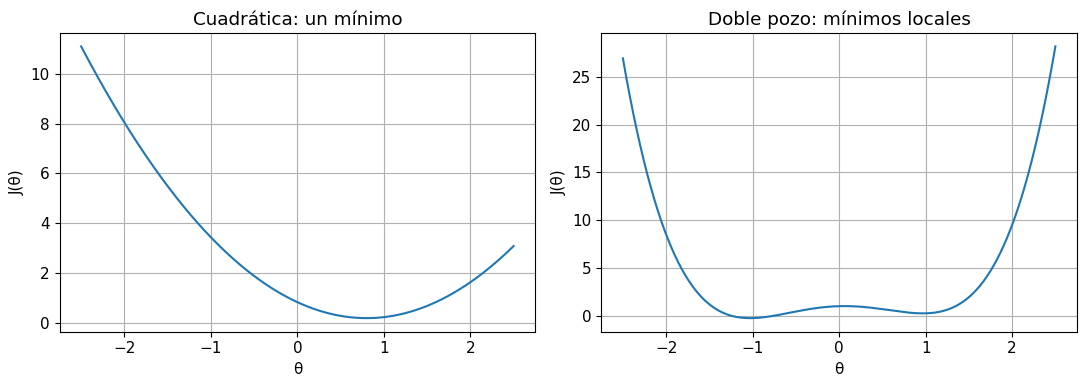

In [2]:
x = np.linspace(-2.5, 2.5, 500)
convexa = (x - 0.8)**2 + 0.2
no_convexa = (x*x - 1)**2 + 0.25*x
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(x, convexa); ax[0].set(title='Cuadrática: un mínimo', xlabel='θ', ylabel='J(θ)')
ax[1].plot(x, no_convexa); ax[1].set(title='Doble pozo: mínimos locales', xlabel='θ', ylabel='J(θ)')
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

**Lectura de la figura.** En la cuadrática cualquier descenso bien controlado se dirige al mismo valle. El doble pozo tiene dos cuencas y la inicialización puede decidir en cuál acaba un método local. No confundas un tramo plano en la imagen con derivada exactamente nula.

## 3. Condiciones de primer y segundo orden

Para un mínimo interior diferenciable, $\nabla J(\theta^*)=0$. Esta condición también se cumple en máximos y puntos silla. Si además $J$ es dos veces diferenciable, un mínimo local requiere que el Hessiano sea semidefinido positivo. Un Hessiano definido positivo en un punto estacionario es condición suficiente de mínimo local estricto.

El desarrollo de Taylor explica estas condiciones:

$$J(\theta+p)=J(\theta)+\nabla J(\theta)^Tp+\tfrac12p^TH(\theta)p+o(\|p\|^2).$$

El término lineal proporciona una dirección de descenso; el cuadrático describe curvatura. Si el Hessiano tiene autovalores de ambos signos, existe una dirección que aumenta y otra que reduce el objetivo: es un punto silla.

## 4. Ejemplo cuadrático resuelto a mano

Para $J(\theta)=\tfrac12\theta^TA\theta-b^T\theta$, con $A$ simétrica definida positiva, $\nabla J=A\theta-b$ y $H=A$. Resolver $A\theta^*=b$ da el mínimo único. Usamos `solve`, no calculamos explícitamente $A^{-1}$: resolver el sistema evita trabajo y errores innecesarios.

Minimizador: [0. 1.]
Gradiente: [0. 0.]
Autovalores de H: [1.58579 4.41421]


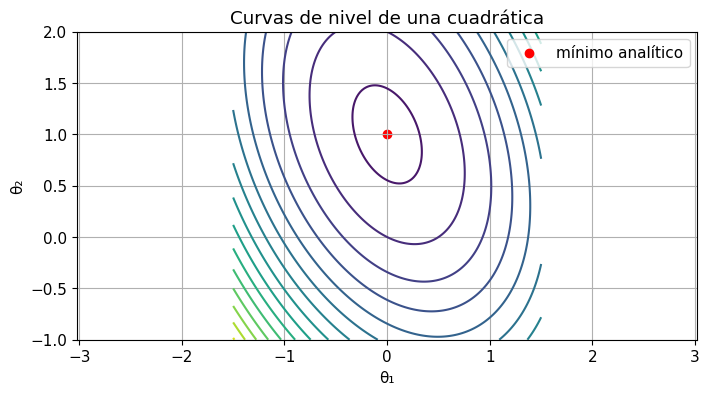

In [3]:
A = np.array([[4., 1.], [1., 2.]])
b = np.array([1., 2.])
theta_star = np.linalg.solve(A, b)
def J(theta):
    theta = np.asarray(theta)
    return 0.5*np.einsum('...i,ij,...j->...', theta, A, theta) - theta @ b
print('Minimizador:', theta_star)
print('Gradiente:', A @ theta_star - b)
print('Autovalores de H:', np.linalg.eigvalsh(A))
u, v = np.meshgrid(np.linspace(-1.5, 1.5, 180), np.linspace(-1, 2, 180))
z = J(np.stack([u, v], axis=-1))
plt.contour(u, v, z, levels=18)
plt.scatter(*theta_star, c='red', label='mínimo analítico')
plt.xlabel('θ₁'); plt.ylabel('θ₂'); plt.title('Curvas de nivel de una cuadrática')
plt.legend(); plt.axis('equal'); plt.show()

**Interpretación.** Las elipses muestran las direcciones de curvatura del Hessiano. El gradiente es perpendicular a cada curva de nivel; no apunta necesariamente directamente al centro en coordenadas euclídeas. Los autovalores positivos certifican convexidad de esta cuadrática en todo $\mathbb R^2$.

## 5. Optimización y estimación estadística

Si observamos $y_i=f_\theta(x_i)+\epsilon_i$ y suponemos errores independientes gaussianos con desviación $\sigma$, minimizar

$$J(\theta)=\frac1{2\sigma^2}\sum_i[f_\theta(x_i)-y_i]^2$$

equivale a maximizar la verosimilitud. La equivalencia usa esa hipótesis de ruido; errores heterogéneos requieren pesos y valores atípicos pueden justificar pérdidas robustas.

Una regularización $\lambda\|\theta\|^2$ introduce una preferencia por ciertos parámetros y cambia el problema. No mejora necesariamente cada ajuste observado: controla inestabilidad o complejidad. En SciML las variables pueden ser coeficientes de difusión y las predicciones pueden requerir resolver una ODE.

## 6. Caso científico: decaimiento exponencial

El balance $du/dt=-ku$, $u(0)=1$, produce $u(t;k)=e^{-kt}$. $k$ tiene unidades de tiempo inverso y debe ser no negativo para un decaimiento. Generamos mediciones con $k=0.7$, añadimos ruido y ajustamos únicamente el conjunto de entrenamiento.

k real / estimado: 0.7 0.6936178668378551
MSE entrenamiento: 0.0003655536261640322
MSE datos reservados: 0.00042791506216894036


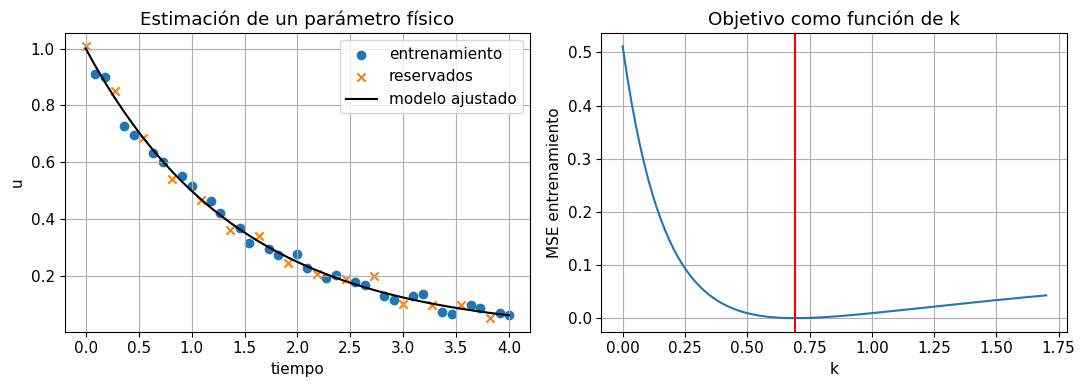

In [4]:
t = np.linspace(0, 4, 45)
k_true = 0.7
y = np.exp(-k_true*t) + rng.normal(0, 0.025, len(t))
train = np.arange(len(t)) % 3 != 0
def loss(k, mask=train):
    return np.mean((np.exp(-float(k)*t[mask]) - y[mask])**2)
res = optimize.minimize_scalar(loss, bounds=(0, 2), method='bounded')
k_hat = res.x
assert res.success
print('k real / estimado:', k_true, k_hat)
print('MSE entrenamiento:', loss(k_hat))
print('MSE datos reservados:', loss(k_hat, ~train))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(t[train], y[train], label='entrenamiento')
ax[0].scatter(t[~train], y[~train], marker='x', label='reservados')
ax[0].plot(t, np.exp(-k_hat*t), 'k', label='modelo ajustado')
ax[0].set(xlabel='tiempo', ylabel='u', title='Estimación de un parámetro físico'); ax[0].legend()
k_grid = np.linspace(0, 1.7, 200)
ax[1].plot(k_grid, [loss(k) for k in k_grid]); ax[1].axvline(k_hat, c='r')
ax[1].set(xlabel='k', ylabel='MSE entrenamiento', title='Objetivo como función de k')
plt.tight_layout(); plt.show()

**Interpretación.** La curva sigue la tendencia del decaimiento sin atravesar cada medición. El mínimo del gráfico es compatible con el resultado del optimizador. La cercanía a $k_{\rm real}$ es verificable porque aquí conocemos la verdad sintética; en datos reales se debe evaluar identificabilidad e incertidumbre.

## 7. Un resultado de software necesita comprobaciones

`success=True` comunica que se cumplió un criterio del algoritmo, no una garantía universal de mínimo global. Compara el resultado con una referencia analítica o una malla, examina las restricciones y calcula el residuo. En problemas multidimensionales revisa la norma del gradiente y, cuando sea viable, la curvatura.

El doble pozo permite comprobar la dependencia del inicio de un método local. Para una función no convexa varias inicializaciones son un diagnóstico útil, pero tampoco prueban globalidad.

In [5]:
def double_well(z):
    q = float(z[0]); return (q*q - 1)**2 + 0.25*q
def double_grad(z):
    q = float(z[0]); return np.array([4*q*(q*q-1)+0.25])
for init in [-2., -0.2, 0.5, 2.]:
    r = optimize.minimize(double_well, [init], jac=double_grad, method='BFGS')
    print(f'inicio={init:5.1f} -> θ={r.x[0]: .5f}, J={r.fun:.5f}, |grad|={np.linalg.norm(r.jac):.2e}')

inicio= -2.0 -> θ=-1.02990, J=-0.25379, |grad|=1.18e-06
inicio= -0.2 -> θ=-1.02990, J=-0.25379, |grad|=7.86e-06
inicio=  0.5 -> θ= 0.96715, J=0.24596, |grad|=1.31e-06
inicio=  2.0 -> θ= 0.96715, J=0.24596, |grad|=8.61e-08


## 8. Sensibilidad: información disponible en los datos

La sensibilidad del decaimiento es $\partial u/\partial k=-t e^{-kt}$. Es cero en $t=0$: una medición inicial no informa sobre $k$ si $u(0)$ es conocido. Para tiempos muy grandes también es pequeña porque el estado casi se ha extinguido. Medir alrededor de $t=1/k$ aporta mayor sensibilidad absoluta.

Esta observación conecta optimización con diseño experimental. Más mediciones no equivalen automáticamente a más información si todas se toman en una región insensible. El cálculo siguiente mide la variación del objetivo alrededor del ajuste con una segunda diferencia; no debe confundirse con un intervalo de confianza completo.

In [6]:
h = 1e-4
curvature = (loss(k_hat+h) - 2*loss(k_hat) + loss(k_hat-h))/h**2
sensitivity = -t*np.exp(-k_hat*t)
print('Curvatura local del objetivo:', curvature)
print('Tiempo de máxima sensibilidad en esta malla:', t[np.argmax(np.abs(sensitivity))])
assert curvature > 0
assert np.allclose(A @ theta_star, b)
assert 0 <= k_hat <= 2

Curvatura local del objetivo: 0.3358047900240812
Tiempo de máxima sensibilidad en esta malla: 1.4545454545454546


## 9. Escalas, tolerancias y reproducibilidad

Sumar errores de temperatura en kelvin y velocidad en metros por segundo sin normalización introduce una elección oculta de pesos. Una variable con valores del orden de $10^6$ y otra del orden de $10^{-3}$ puede producir una geometría difícil incluso con un modelo sencillo. Adimensionalizar parámetros y residuos suele mejorar la interpretación y el comportamiento numérico.

Distingue tolerancia del optimizador, error de discretización del modelo y ruido experimental. Reducir una tolerancia por debajo de la precisión de la simulación no crea información nueva. Guarda función objetivo, rango de parámetros, semilla y criterio de validación para poder reproducir el ajuste.

## Síntesis y conexión con Scientific Machine Learning

Una pérdida convierte una pregunta científica en un problema numérico. Convexidad, sensibilidad y restricciones determinan qué significa la solución. En PINNs se minimizan simultáneamente residuos físicos y errores de datos; las mismas preguntas de escala, existencia e identificabilidad siguen presentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_4_Spectral_Methods.ipynb) | [⏩](../10_OPTIMIZACION/10_2_Gradient_methods.ipynb) |